# Video Anomaly Detection using Multiple Instance Learning (MIL)

This notebook mirrors the LSTM notebook's workflow, paths, preprocessing, train/validation/test split, metrics, plots, and inference — replacing the LSTM with **Multiple Instance Learning (MIL)**.

**Dataset:** `~/Desktop/archive/All_Data`  
**Notebook location:** `~/Desktop/urop1/video_anomaly_mil.ipynb`  
**Labels:** `0 = Normal`, `1 = Anomaly`

MIL treats each video as a **bag** of temporal feature segments (instances). It trains using only the video-level label. The model assigns a score to each segment and aggregates segment scores into a video-level score using max pooling. The segment scores are useful for anomaly timelines, but without temporal ground-truth annotations they should not be interpreted as verified frame-level predictions.

## 1. Imports and setup

If a dependency is missing, run the installation cell. Python 3.14 compatibility varies by package; if installation fails, use a Python version supported by the installed PyTorch release.

In [1]:
%pip install -U numpy pandas matplotlib scikit-learn torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve, precision_recall_fscore_support
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_ROOT = Path.home() / "Desktop" / "archive" / "All_Data"
PROJECT_DIR = Path.home() / "Desktop" / "urop1"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = PROJECT_DIR / "best_mil_model.pt"

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Dataset root:", DATA_ROOT)
print("Project directory:", PROJECT_DIR)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("MPS available:", torch.backends.mps.is_available())

if not DATA_ROOT.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_ROOT}")

Dataset root: /Users/administrator/Desktop/archive/All_Data
Project directory: /Users/administrator/Desktop/urop1
PyTorch: 2.14.1
Device: mps
MPS available: True


## 2. Inspect the dataset

In [3]:
all_files = [p for p in DATA_ROOT.rglob("*") if p.is_file()]
print(f"Total files: {len(all_files):,}")
for p in all_files[:40]:
    print(p.relative_to(DATA_ROOT))

txt_files = [p for p in all_files if p.suffix.lower() == ".txt"]
print(f"\nTXT files: {len(txt_files):,}")
print("\nLikely split / annotation files:")
for p in txt_files:
    if any(k in p.name.lower() for k in ["train", "test", "split", "annotation", "label"]):
        print(p.relative_to(DATA_ROOT))

Total files: 1,904
.DS_Store
All_Data/.DS_Store
All_Data/Normal_Train.txt
All_Data/Anomaly_Train.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_597_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_890_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_015_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_722_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_905_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_932_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_873_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_360_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_018_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_941_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_923_x264_C.txt
All_Data/Testing_Normal_Videos_Anomaly_txt/Normal_Videos_914_x264_C.txt
All_Data/Testing_Normal_Videos_Anom

## 3. Find numeric temporal feature matrices

Expected format is typically `(32, 4096)` per video. The notebook detects matrices from the actual files rather than hardcoding a fixed count.

In [4]:
def try_load_feature_file(path):
    try:
        arr = np.loadtxt(path, dtype=np.float32)
        if arr.ndim == 2 and arr.shape[0] >= 2 and arr.shape[1] >= 2 and np.isfinite(arr).all():
            return arr
    except Exception:
        pass
    return None

feature_records = []
for p in txt_files:
    arr = try_load_feature_file(p)
    if arr is not None:
        feature_records.append({
            "path": p,
            "relative_path": str(p.relative_to(DATA_ROOT)),
            "video_id": p.stem,
            "shape": tuple(arr.shape),
            "features": arr
        })

print("Numeric feature matrices found:", len(feature_records))
print("Most common shapes:", Counter(r["shape"] for r in feature_records).most_common(10))
if not feature_records:
    raise RuntimeError("No numeric 2-D feature matrices found. Inspect the dataset structure.")
display(pd.DataFrame([
    {"relative_path": r["relative_path"], "video_id": r["video_id"], "shape": str(r["shape"])}
    for r in feature_records[:15]
]))

Numeric feature matrices found: 1900
Most common shapes: [((32, 4096), 1900)]


,relative_path,video_id,shape
0,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_597_x264_C,"(32, 4096)"
1,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_890_x264_C,"(32, 4096)"
2,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_015_x264_C,"(32, 4096)"
3,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_722_x264_C,"(32, 4096)"
4,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_905_x264_C,"(32, 4096)"
5,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_932_x264_C,"(32, 4096)"
6,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_873_x264_C,"(32, 4096)"
7,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_360_x264_C,"(32, 4096)"
8,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_018_x264_C,"(32, 4096)"
9,All_Data/Testing_Normal_Videos_Anomaly_txt/Nor...,Normal_Videos_941_x264_C,"(32, 4096)"


## 4. Infer video labels from folder/path names

The class mapping is `0 = Normal`, `1 = Anomaly`. Check the summaries and unresolved paths before training.

In [5]:
ANOMALY_CATEGORIES = {
    "abuse", "arrest", "arson", "assault", "burglary", "explosion", "fighting",
    "robbery", "shooting", "shoplifting", "stealing", "vandalism", "roadaccidents",
    "roadaccident", "accident", "terrorism", "weapon"
}
def norm_token(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())

def infer_label(path):
    parts = [norm_token(part) for part in path.parts]
    if any(p == "normal" or p.startswith("trainingnormal") or p.startswith("testingnormal") for p in parts):
        return 0, "normal_folder"
    for p in parts[:-1]:
        if p in ANOMALY_CATEGORIES or any(p.startswith(cat) for cat in ANOMALY_CATEGORIES):
            return 1, "anomaly_category"
    if any("anomaly" in p for p in parts[:-1]):
        return 1, "anomaly_parent"
    if "normal" in "/".join(parts):
        return 0, "normal_path"
    return None, "unknown"

for rec in feature_records:
    rec["label"], rec["label_source"] = infer_label(rec["path"])

print("Raw label counts:", Counter(str(r["label"]) for r in feature_records))
print("Label sources:", Counter(r["label_source"] for r in feature_records))
unknown = [r for r in feature_records if r["label"] is None]
if unknown:
    print("\nUnresolved examples:")
    for r in unknown[:30]:
        print(r["relative_path"])

records = [r for r in feature_records if r["label"] in (0, 1)]
if len({r["label"] for r in records}) < 2:
    raise RuntimeError("Both classes were not detected. Adjust infer_label() to match your folders.")
print("Usable labelled videos:", len(records))
print("Usable class counts:", Counter(r["label"] for r in records))

Raw label counts: Counter({'0': 950, '1': 950})
Label sources: Counter({'normal_folder': 950, 'anomaly_category': 950})
Usable labelled videos: 1900
Usable class counts: Counter({0: 950, 1: 950})


## 5. Explore class balance and one feature matrix

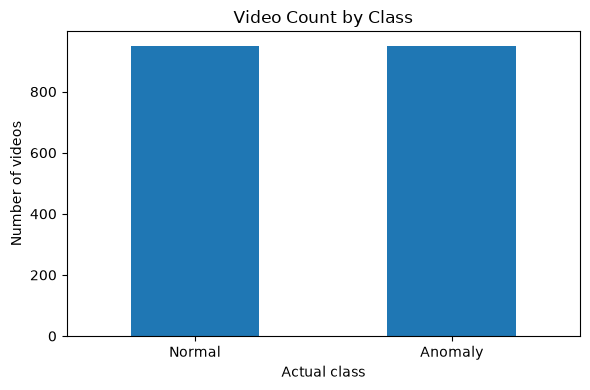

Example: Normal_Videos_597_x264_C | shape: (32, 4096)
Min/max/mean/std: 0.0 0.13075600564479828 0.006569992750883102 0.014176595956087112


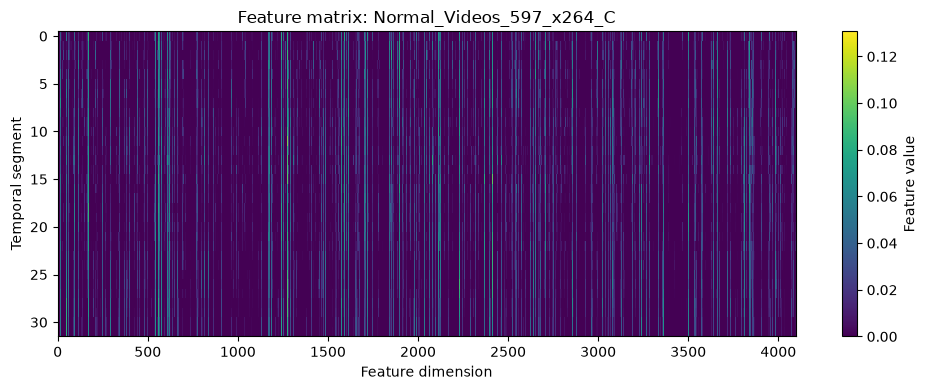

In [6]:
class_counts = pd.Series([r["label"] for r in records]).map({0:"Normal", 1:"Anomaly"}).value_counts()
plt.figure(figsize=(6,4))
class_counts.reindex(["Normal", "Anomaly"]).plot(kind="bar")
plt.title("Video Count by Class")
plt.xlabel("Actual class")
plt.ylabel("Number of videos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

example = records[0]["features"]
print("Example:", records[0]["video_id"], "| shape:", example.shape)
print("Min/max/mean/std:", float(example.min()), float(example.max()), float(example.mean()), float(example.std()))
plt.figure(figsize=(10,4))
plt.imshow(example, aspect="auto", interpolation="nearest")
plt.title(f"Feature matrix: {records[0]['video_id']}")
plt.xlabel("Feature dimension")
plt.ylabel("Temporal segment")
plt.colorbar(label="Feature value")
plt.tight_layout()
plt.show()

## 6. Train / validation / test split

Like the LSTM notebook, this uses a reproducible stratified 70/15/15 split at the video level. It inspects possible official split files but does not automatically parse their variable formats.

In [7]:
split_candidates = [
    p for p in txt_files
    if any(k in p.name.lower() for k in ["train", "test", "split"])
    and try_load_feature_file(p) is None
]
print("Potential split files:", len(split_candidates))
for p in split_candidates[:20]:
    print("\n---", p.relative_to(DATA_ROOT), "---")
    try:
        print("\n".join(p.read_text(errors="ignore").splitlines()[:5]))
    except Exception as e:
        print("Could not read:", e)

labels = np.array([r["label"] for r in records], dtype=np.int64)
indices = np.arange(len(records))
train_idx, temp_idx = train_test_split(indices, test_size=0.30, random_state=SEED, stratify=labels)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED, stratify=labels[temp_idx])
train_records = [records[i] for i in train_idx]
val_records = [records[i] for i in val_idx]
test_records = [records[i] for i in test_idx]

def show_split(name, subset):
    c = Counter(r["label"] for r in subset)
    print(f"{name:>10}: {len(subset):4d} videos | Normal={c.get(0,0)} | Anomaly={c.get(1,0)}")
show_split("Train", train_records)
show_split("Validation", val_records)
show_split("Test", test_records)

Potential split files: 2

--- All_Data/Normal_Train.txt ---
Training-Normal-Videos-Part-1-txt/Normal_Videos001_x264_C.txt
Training-Normal-Videos-Part-1-txt/Normal_Videos002_x264_C.txt
Training-Normal-Videos-Part-1-txt/Normal_Videos004_x264_C.txt
Training-Normal-Videos-Part-1-txt/Normal_Videos005_x264_C.txt
Training-Normal-Videos-Part-1-txt/Normal_Videos007_x264_C.txt

--- All_Data/Anomaly_Train.txt ---
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse001_x264_C.txt
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse002_x264_C.txt
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse003_x264_C.txt
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse004_x264_C.txt
Anomaly-Vidoes-Part-1-txt/Abuse/Abuse005_x264_C.txt
     Train: 1330 videos | Normal=665 | Anomaly=665
Validation:  285 videos | Normal=142 | Anomaly=143
      Test:  285 videos | Normal=143 | Anomaly=142


## 7. Normalize features and create MIL bags

Each video is a bag containing a sequence of feature vectors. We standardize features using training data only, then sample/pad to a common sequence length.

In [8]:
feature_dims = Counter(r["features"].shape[1] for r in records)
print("Feature dimension counts:", feature_dims)
if len(feature_dims) != 1:
    raise ValueError("Feature dimensions differ across files; align them before MIL training.")
INPUT_DIM = next(iter(feature_dims))
SEQ_LEN = int(np.median([r["features"].shape[0] for r in train_records]))
print("Input dimension:", INPUT_DIM, "| instances per bag:", SEQ_LEN)

train_rows = np.concatenate([r["features"] for r in train_records], axis=0)
FEATURE_MEAN = train_rows.mean(axis=0, keepdims=True)
FEATURE_STD = train_rows.std(axis=0, keepdims=True)
FEATURE_STD[FEATURE_STD < 1e-6] = 1.0

def prepare_bag(arr):
    arr = np.asarray(arr, dtype=np.float32)
    arr = (arr - FEATURE_MEAN) / FEATURE_STD
    if len(arr) >= SEQ_LEN:
        idx = np.linspace(0, len(arr)-1, SEQ_LEN).round().astype(int)
        arr = arr[idx]
    else:
        arr = np.concatenate([arr, np.zeros((SEQ_LEN-len(arr), arr.shape[1]), dtype=np.float32)], axis=0)
    return arr.astype(np.float32)

class VideoBagDataset(Dataset):
    def __init__(self, subset):
        self.subset = subset
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        rec = self.subset[idx]
        return torch.from_numpy(prepare_bag(rec["features"])), torch.tensor(float(rec["label"])), rec["video_id"]

BATCH_SIZE = 8
train_loader = DataLoader(VideoBagDataset(train_records), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(VideoBagDataset(val_records), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(VideoBagDataset(test_records), batch_size=BATCH_SIZE, shuffle=False)
xb, yb, ids = next(iter(train_loader))
print("MIL batch shape (batch, instances, feature_dim):", tuple(xb.shape))
print("Labels:", yb.tolist())

Feature dimension counts: Counter({4096: 1900})
Input dimension: 4096 | instances per bag: 32
MIL batch shape (batch, instances, feature_dim): (8, 32, 4096)
Labels: [1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 1.0]


## 8. Define a Multiple Instance Learning model

Each instance is scored independently by a small neural network. The bag/video anomaly score is the maximum instance score (**max pooling**), reflecting the MIL assumption that a video is anomalous when at least one temporal segment is anomalous.

In [9]:
class VideoAnomalyMIL(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.instance_scorer = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        # x: [batch, instances, feature_dim]
        instance_logits = self.instance_scorer(x).squeeze(-1)
        instance_probs = torch.sigmoid(instance_logits)
        bag_probs = torch.max(instance_probs, dim=1).values
        # Return bag logits for stable BCE loss and per-instance probabilities for plots.
        eps = 1e-6
        bag_probs_clamped = bag_probs.clamp(eps, 1-eps)
        bag_logits = torch.logit(bag_probs_clamped)
        return bag_logits, instance_logits

HIDDEN_DIM = 128
model = VideoAnomalyMIL(INPUT_DIM, hidden_dim=HIDDEN_DIM).to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

VideoAnomalyMIL(
  (instance_scorer): Sequential(
    (0): Linear(in_features=4096, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)
Trainable parameters: 524545


## 9. Train MIL model

Only video-level labels are used in the loss. The model's per-instance scores are latent estimates, not segment-supervised labels. Best checkpoint is selected by validation loss.

In [10]:
EPOCHS = 20
LEARNING_RATE = 1e-4
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-5)
history = {k: [] for k in ["train_loss", "val_loss", "train_accuracy", "val_accuracy", "train_auc", "val_auc"]}
best_val_loss = float("inf")
best_epoch = 0

def run_epoch(loader, training):
    model.train(training)
    total_loss, total_count = 0.0, 0
    all_y, all_prob = [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for xb, yb, _ in loader:
            xb = xb.to(DEVICE, dtype=torch.float32)
            yb = yb.to(DEVICE, dtype=torch.float32)
            if training:
                optimizer.zero_grad(set_to_none=True)
            bag_logits, _ = model(xb)
            loss = criterion(bag_logits, yb)
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
            probs = torch.sigmoid(bag_logits)
            total_loss += loss.item() * len(yb)
            total_count += len(yb)
            all_y.extend(yb.detach().cpu().numpy().astype(int).tolist())
            all_prob.extend(probs.detach().cpu().numpy().tolist())
    y_true, y_prob = np.asarray(all_y), np.asarray(all_prob)
    y_pred = (y_prob >= 0.5).astype(int)
    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else float("nan")
    return total_loss/max(total_count, 1), accuracy_score(y_true, y_pred), auc

for epoch in range(1, EPOCHS+1):
    train_loss, train_acc, train_auc = run_epoch(train_loader, True)
    val_loss, val_acc, val_auc = run_epoch(val_loader, False)
    for k, v in [
        ("train_loss", train_loss), ("val_loss", val_loss),
        ("train_accuracy", train_acc), ("val_accuracy", val_acc),
        ("train_auc", train_auc), ("val_auc", val_auc)
    ]:
        history[k].append(v)

    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "input_dim": INPUT_DIM,
            "hidden_dim": HIDDEN_DIM,
            "seq_len": SEQ_LEN,
            "feature_mean": FEATURE_MEAN,
            "feature_std": FEATURE_STD,
            "best_val_loss": best_val_loss
        }, CHECKPOINT_PATH)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.3f} val_loss={val_loss:.4f} "
        f"val_acc={val_acc:.3f} val_auc={val_auc:.3f}"
        + (" [best checkpoint]" if epoch == best_epoch else "")
    )

print("Best epoch:", best_epoch, "| best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", CHECKPOINT_PATH)

Epoch 01/20 | train_loss=0.5434 train_acc=0.714 val_loss=0.3875 val_acc=0.849 val_auc=0.922 [best checkpoint]
Epoch 02/20 | train_loss=0.3595 train_acc=0.848 val_loss=0.3439 val_acc=0.849 val_auc=0.929 [best checkpoint]
Epoch 03/20 | train_loss=0.2729 train_acc=0.904 val_loss=0.3286 val_acc=0.870 val_auc=0.933 [best checkpoint]
Epoch 04/20 | train_loss=0.2072 train_acc=0.938 val_loss=0.3147 val_acc=0.881 val_auc=0.937 [best checkpoint]
Epoch 05/20 | train_loss=0.1605 train_acc=0.956 val_loss=0.3095 val_acc=0.881 val_auc=0.940 [best checkpoint]
Epoch 06/20 | train_loss=0.1149 train_acc=0.980 val_loss=0.3212 val_acc=0.870 val_auc=0.937
Epoch 07/20 | train_loss=0.0883 train_acc=0.987 val_loss=0.3297 val_acc=0.877 val_auc=0.936
Epoch 08/20 | train_loss=0.0667 train_acc=0.990 val_loss=0.3318 val_acc=0.884 val_auc=0.938
Epoch 09/20 | train_loss=0.0513 train_acc=0.995 val_loss=0.3365 val_acc=0.881 val_auc=0.939
Epoch 10/20 | train_loss=0.0398 train_acc=0.996 val_loss=0.3468 val_acc=0.884 val_

## 10. Plot train / validation loss, accuracy, and ROC-AUC

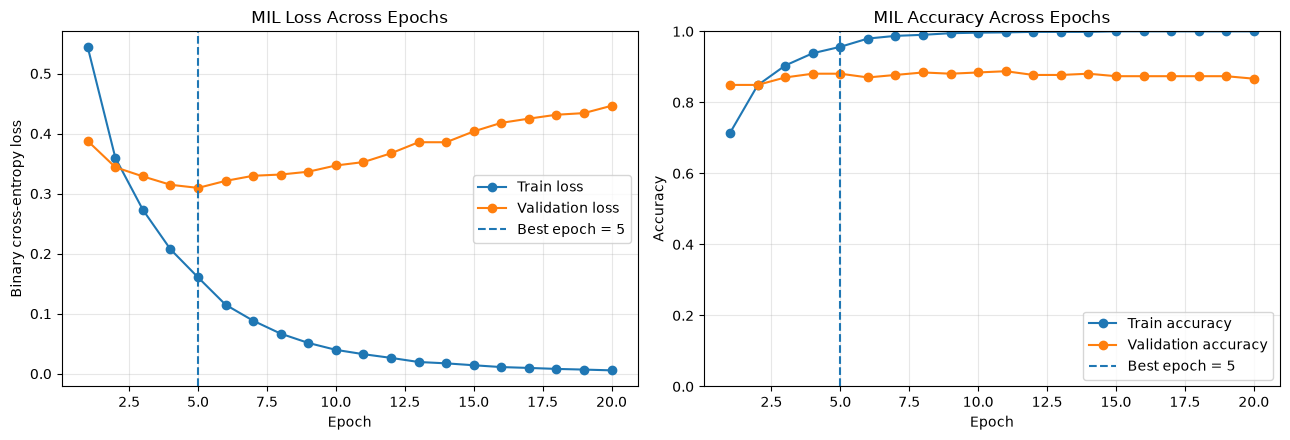

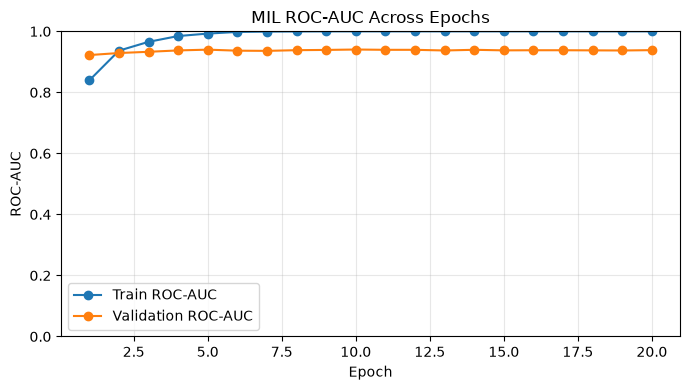

In [11]:
epochs_axis = np.arange(1, len(history["train_loss"])+1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs_axis, history["train_loss"], marker="o", label="Train loss")
axes[0].plot(epochs_axis, history["val_loss"], marker="o", label="Validation loss")
axes[0].axvline(best_epoch, linestyle="--", label=f"Best epoch = {best_epoch}")
axes[0].set_title("MIL Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_axis, history["train_accuracy"], marker="o", label="Train accuracy")
axes[1].plot(epochs_axis, history["val_accuracy"], marker="o", label="Validation accuracy")
axes[1].axvline(best_epoch, linestyle="--", label=f"Best epoch = {best_epoch}")
axes[1].set_title("MIL Accuracy Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,4))
plt.plot(epochs_axis, history["train_auc"], marker="o", label="Train ROC-AUC")
plt.plot(epochs_axis, history["val_auc"], marker="o", label="Validation ROC-AUC")
plt.title("MIL ROC-AUC Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Load best checkpoint and evaluate on the held-out test set

In [12]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print("Loaded checkpoint from epoch:", checkpoint["epoch"])

test_y, test_prob, test_ids, test_segment_scores = [], [], [], []
with torch.no_grad():
    for xb, yb, batch_ids in test_loader:
        xb = xb.to(DEVICE, dtype=torch.float32)
        bag_logits, instance_logits = model(xb)
        bag_probs = torch.sigmoid(bag_logits).cpu().numpy()
        instance_probs = torch.sigmoid(instance_logits).cpu().numpy()
        test_y.extend(yb.numpy().astype(int).tolist())
        test_prob.extend(bag_probs.tolist())
        test_ids.extend(list(batch_ids))
        test_segment_scores.extend(instance_probs.tolist())

test_y = np.asarray(test_y, dtype=int)
test_prob = np.asarray(test_prob, dtype=float)
test_pred = (test_prob >= 0.5).astype(int)
print("Test videos:", len(test_y))
print("Test accuracy:", f"{accuracy_score(test_y, test_pred):.4f}")
if len(np.unique(test_y)) == 2:
    print("Test ROC-AUC:", f"{roc_auc_score(test_y, test_prob):.4f}")
print("\nClassification report:")
print(classification_report(test_y, test_pred, labels=[0,1],
                            target_names=["Normal", "Anomaly"], zero_division=0))

test_results = pd.DataFrame({
    "video_id": test_ids,
    "actual_label": test_y,
    "predicted_label": test_pred,
    "anomaly_probability": test_prob,
    "predicted_class": np.where(test_pred == 1, "Anomaly", "Normal")
})
display(test_results.head(20))
test_results.to_csv(PROJECT_DIR / "mil_test_predictions.csv", index=False)

Loaded checkpoint from epoch: 5
Test videos: 285
Test accuracy: 0.8351
Test ROC-AUC: 0.8923

Classification report:
              precision    recall  f1-score   support

      Normal       0.82      0.87      0.84       143
     Anomaly       0.86      0.80      0.83       142

    accuracy                           0.84       285
   macro avg       0.84      0.83      0.83       285
weighted avg       0.84      0.84      0.83       285



,video_id,actual_label,predicted_label,anomaly_probability,predicted_class
0,Arson048_x264_C,1,1,0.974307,Anomaly
1,Normal_Videos552_x264_C,0,0,0.019998,Normal
2,Normal_Videos468_x264_C,0,0,0.264653,Normal
3,Burglary085_x264_C,1,0,0.177404,Normal
4,Arrest006_x264_C,1,1,0.999175,Anomaly
5,Normal_Videos_758_x264_C,0,0,0.041112,Normal
6,Normal_Videos336_x264_C,0,0,0.187844,Normal
7,Normal_Videos918_x264_C,0,0,0.276169,Normal
8,Normal_Videos_246_x264_C,0,0,0.117716,Normal
9,Robbery139_x264_C,1,1,0.963386,Anomaly


## 12. Confusion matrix

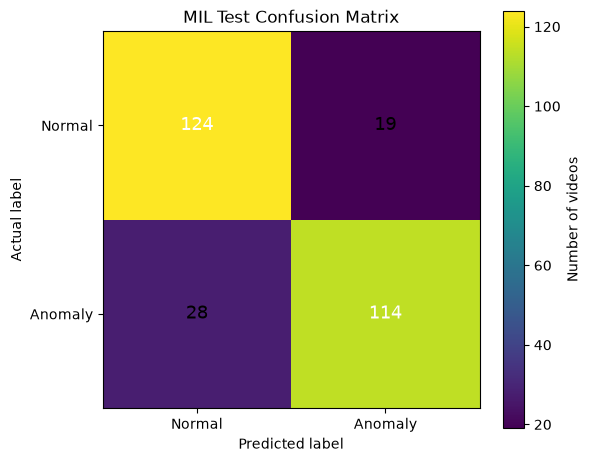

In [14]:
cm = confusion_matrix(test_y, test_pred, labels=[0,1])
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("MIL Test Confusion Matrix")
fig.colorbar(im, ax=ax, label="Number of videos")
classes = ["Normal", "Anomaly"]
ax.set_xticks([0,1], labels=classes)
ax.set_yticks([0,1], labels=classes)
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
threshold = cm.max()/2 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i,j]), ha="center", va="center",
                color="white" if cm[i,j] > threshold else "black", fontsize=13)
plt.tight_layout()
plt.show()

## 13. ROC curve and class-wise metrics

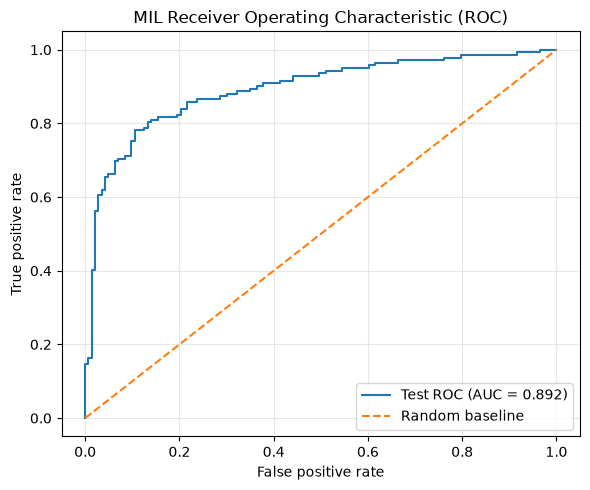

,Precision,Recall,F1-score,Support
Class,,,,
Normal,0.816,0.867,0.841,143
Anomaly,0.857,0.803,0.829,142


In [15]:
if len(np.unique(test_y)) == 2:
    fpr, tpr, _ = roc_curve(test_y, test_prob)
    auc_value = roc_auc_score(test_y, test_prob)
    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, label=f"Test ROC (AUC = {auc_value:.3f})")
    plt.plot([0,1], [0,1], linestyle="--", label="Random baseline")
    plt.title("MIL Receiver Operating Characteristic (ROC)")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

prec, rec, f1, support = precision_recall_fscore_support(
    test_y, test_pred, labels=[0,1], zero_division=0
)
metric_df = pd.DataFrame({
    "Class": ["Normal", "Anomaly"],
    "Precision": prec, "Recall": rec, "F1-score": f1, "Support": support
})
display(metric_df.set_index("Class").style.format({
    "Precision":"{:.3f}", "Recall":"{:.3f}", "F1-score":"{:.3f}", "Support":"{:.0f}"
}))

## 14. Actual video label vs. estimated temporal instance scores

MIL learns only video-level labels. The temporal scores are instance-level estimates aggregated by max pooling; they are not verified frame labels unless temporal ground truth is available.

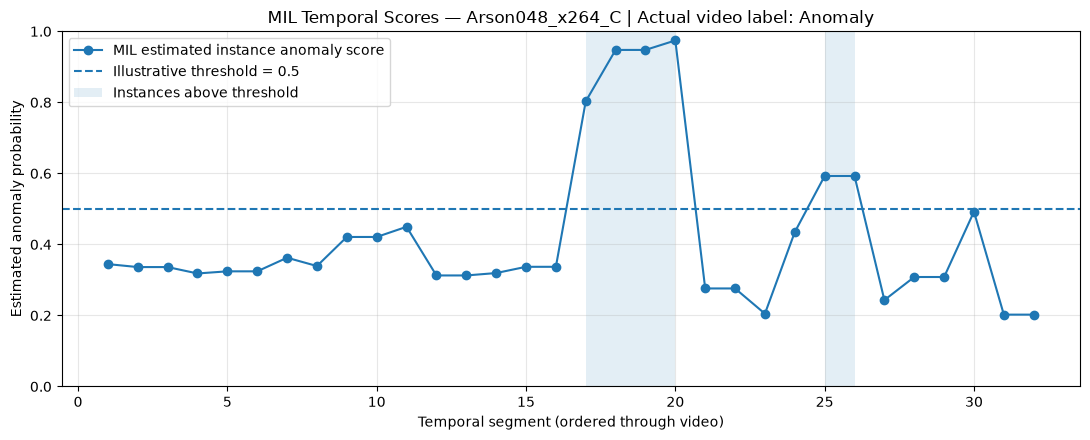

In [16]:
candidate_indices = np.where(test_y == 1)[0]
plot_i = int(candidate_indices[0]) if len(candidate_indices) else 0
chosen_id = test_ids[plot_i]
chosen_actual = int(test_y[plot_i])
chosen_scores = np.asarray(test_segment_scores[plot_i])
xs = np.arange(1, len(chosen_scores)+1)

fig, ax = plt.subplots(figsize=(11,4.5))
ax.plot(xs, chosen_scores, marker="o", label="MIL estimated instance anomaly score")
ax.axhline(0.5, linestyle="--", label="Illustrative threshold = 0.5")
ax.fill_between(xs, 0, 1, where=chosen_scores >= 0.5, alpha=0.12,
                transform=ax.get_xaxis_transform(), label="Instances above threshold")
ax.set_ylim(0,1)
ax.set_title(f"MIL Temporal Scores — {chosen_id} | Actual video label: {'Anomaly' if chosen_actual else 'Normal'}")
ax.set_xlabel("Temporal segment (ordered through video)")
ax.set_ylabel("Estimated anomaly probability")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Inspect optional temporal annotations

If temporal annotation files exist, inspect their format before mapping frame ranges to segments. Do not treat video-level labels as frame-level ground truth.

In [18]:
annotation_files = [
    p for p in DATA_ROOT.rglob("*")
    if p.is_file() and "temporal" in p.name.lower() and "annotation" in p.name.lower()
]
if not annotation_files:
    print("No temporal annotation file found under DATA_ROOT.")
else:
    annotation_path = annotation_files[0]
    print("Found:", annotation_path)
    print("\n".join(annotation_path.read_text(errors="ignore").splitlines()[:30]))
    print("\nAdapt a parser for the actual columns before computing frame/segment-level metrics.")

No temporal annotation file found under DATA_ROOT.


## 16. Reusable inference function

Pass a numeric feature matrix file from the same feature extractor / feature representation used for training.

In [19]:
def predict_video_feature_file(feature_path, threshold=0.5, show_plot=True):
    feature_path = Path(feature_path)
    arr = try_load_feature_file(feature_path)
    if arr is None:
        raise ValueError(f"Could not read numeric 2-D feature matrix: {feature_path}")
    x = torch.from_numpy(prepare_bag(arr)).unsqueeze(0).to(DEVICE, dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        bag_logits, instance_logits = model(x)
        anomaly_probability = float(torch.sigmoid(bag_logits).item())
        instance_scores = torch.sigmoid(instance_logits).squeeze(0).cpu().numpy()
    pred = int(anomaly_probability >= threshold)
    name = "Anomaly" if pred else "Normal"
    print("File:", feature_path.name)
    print(f"Anomaly probability: {anomaly_probability:.4f}")
    print(f"Prediction (threshold={threshold:.2f}): {name}")
    if show_plot:
        xs = np.arange(1, len(instance_scores)+1)
        plt.figure(figsize=(10,4))
        plt.plot(xs, instance_scores, marker="o", label="MIL instance anomaly score")
        plt.axhline(threshold, linestyle="--", label=f"Threshold = {threshold:.2f}")
        plt.ylim(0,1)
        plt.title(f"MIL inference: {feature_path.stem} — {name}")
        plt.xlabel("Temporal segment")
        plt.ylabel("Estimated anomaly probability")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()
    return {
        "video_id": feature_path.stem,
        "anomaly_probability": anomaly_probability,
        "predicted_label": pred,
        "predicted_class": name,
        "instance_scores": instance_scores
    }

# Example:
# prediction = predict_video_feature_file(records[0]["path"])

## 17. Save training history and artifacts

In [20]:
pd.DataFrame(history).assign(epoch=np.arange(1, len(history["train_loss"])+1)).to_csv(
    PROJECT_DIR / "mil_training_history.csv", index=False
)
print("Saved checkpoint:", CHECKPOINT_PATH)
print("Saved test predictions:", PROJECT_DIR / "mil_test_predictions.csv")
print("Saved training history:", PROJECT_DIR / "mil_training_history.csv")

Saved checkpoint: /Users/administrator/Desktop/urop1/best_mil_model.pt
Saved test predictions: /Users/administrator/Desktop/urop1/mil_test_predictions.csv
Saved training history: /Users/administrator/Desktop/urop1/mil_training_history.csv
